# Neural Network for Rating Search Queries

**Author**: Huy Le

## Project goal

This notebook trains neural-network regression models that assign a quality rating from **0 to 1** to a user search query.

- Ratings near **0** represent vague, unclear, or meaningless queries.
- Ratings near **1** represent clear, specific, and meaningful queries.

## Serialization design

The notebook uses **whole-model Keras serialization** for the trained neural network. To avoid the Windows Unicode error previously encountered while serializing a multilingual `TextVectorization` vocabulary, text preprocessing is kept outside the serialized neural model:

```text
Raw query text
    -> TextVectorization
    -> Integer token sequence
    -> Serialized Keras neural model
    -> Predicted rating
```

The neural model is saved as a complete `.keras` file containing its architecture, trained weights, compilation configuration, and optimizer state. The text-vectorization vocabulary and settings are saved separately as UTF-8 JSON files so the entire prediction pipeline can be reconstructed.

## Data-integrity rule

The notebook treats `train.csv` and `test.csv` as read-only inputs. It does not add columns to or remove columns from the original DataFrames.

In [1]:
"""
MODULE 1: IMPORT LIBRARIES AND CONFIGURE THE PROJECT

Purpose
-------
This module imports the libraries used by the notebook and defines all file
locations and modeling settings in one place.

For nontechnical readers
------------------------
A Python library is a collection of reusable tools. Pandas works with tables,
NumPy works with numerical arrays, Matplotlib creates charts, scikit-learn
provides traditional machine-learning utilities, and TensorFlow/Keras builds
and trains neural networks.

Serialization approach
----------------------
The neural network will accept integer token sequences rather than raw text.
This allows the complete neural network to be serialized as a `.keras` file
without asking Keras to serialize the multilingual vocabulary that triggered
the earlier Windows cp1252 Unicode error.
"""

# Standard Python libraries
import json
import os
import random
import re
import sys
import warnings
from pathlib import Path

# Data-processing and visualization libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Traditional machine-learning tools
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

# Neural-network tools
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Hide noncritical warnings so that notebook output remains readable.
warnings.filterwarnings("ignore")

# A fixed random seed makes data splitting, model initialization, and other
# random operations more consistent between runs.
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Reconfigure notebook output streams where the environment permits it.
# This improves the display of multilingual text on Windows. The model-saving
# fix itself comes from keeping the vocabulary outside the serialized model.
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")
if hasattr(sys.stderr, "reconfigure"):
    sys.stderr.reconfigure(encoding="utf-8", errors="replace")

# Input locations
DATA_DIR = Path("data")
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

# Output locations
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SUBMISSION_PATH = OUTPUT_DIR / "submission.csv"
RESULTS_PATH = OUTPUT_DIR / "model_experiment_results.csv"
FINAL_MODEL_PATH = OUTPUT_DIR / "best_query_rating_model.keras"
VECTORIZER_CONFIG_PATH = OUTPUT_DIR / "text_vectorizer_config.json"
VECTORIZER_VOCABULARY_PATH = OUTPUT_DIR / "text_vectorizer_vocabulary.json"

# Percentage of labeled observations reserved for validation.
VALIDATION_SIZE = 0.20

# Number of observations processed before one weight update.
BATCH_SIZE = 64

# Maximum number of passes through the training dataset.
# Early stopping may end training sooner.
MAX_EPOCHS = 25

# Maximum number of vocabulary tokens retained.
MAX_TOKENS = 20_000

# Number of numerical values used to represent each token.
EMBEDDING_DIM = 64

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)
print("Output directory:", OUTPUT_DIR.resolve())

Python executable: C:\Drive_D\Gia Huy\pythonfiles\HoneywellAIEngineerassessment\venv\Scripts\python.exe
Python version: 3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)]
TensorFlow version: 2.22.0-rc0
Keras version: 3.16.0.dev2026102204
Output directory: C:\Drive_D\Gia Huy\pythonfiles\HoneywellAIEngineerassessment\outputs


In [2]:
"""
MODULE 2: LOAD AND VALIDATE THE DATASETS

Purpose
-------
This module reads the supplied CSV files into memory and confirms that their
columns match the required project schemas exactly.

Variables created
-----------------
data:
    The table loaded from train.csv. It must contain query and rating.

test_data:
    The table loaded from test.csv. It must contain query only.

Source-file safety
------------------
Reading a CSV does not edit the file on disk. The original column names and
shapes are recorded so a later module can prove that the DataFrames were not
structurally modified.
"""

# Identify required files that are missing.
missing_files = [str(path) for path in [TRAIN_PATH, TEST_PATH] if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        "Required file(s) not found: " + ", ".join(missing_files) +
        ". Place train.csv and test.csv in the data folder."
    )

# Load the datasets explicitly as UTF-8
data = pd.read_csv(TRAIN_PATH, encoding="utf-8")
test_data = pd.read_csv(TEST_PATH, encoding="utf-8")

# Validate the exact column schemas
expected_train_columns = ["query", "rating"]
expected_test_columns = ["query"]

if list(data.columns) != expected_train_columns:
    raise ValueError(
        f"train.csv must contain exactly {expected_train_columns}; "
        f"found {data.columns.tolist()}."
    )
if list(test_data.columns) != expected_test_columns:
    raise ValueError(
        f"test.csv must contain exactly {expected_test_columns}; "
        f"found {test_data.columns.tolist()}."
    )

# Record the original structures
original_train_columns = tuple(data.columns)
original_test_columns = tuple(test_data.columns)
original_train_shape = data.shape
original_test_shape = test_data.shape

# Display basic information
print("Training shape:", data.shape)
print("Testing shape:", test_data.shape)
display(data.head())
display(test_data.head())

Training shape: (5000, 2)
Testing shape: (999, 1)


,query,rating
0,where to buy a reliable smartphone,0.9382
1,how to fix a syntax error in rust,0.8168
2,how to calculate mean absolute error in C#,0.8305
3,best electric vehicles resources,0.6663
4,wireless headphones examples,0.4834


,query
0,NaN
1,x
2,?
3,12345
4,weather


In [3]:
"""
MODULE 3: CREATE CLEAN MODELING ARRAYS

Purpose
-------
This module creates separate arrays for cleaned training queries, ratings, and
test queries. Nothing is assigned back to the original DataFrames.

Cleaning behavior
-----------------
The cleaning function replaces missing query values with an empty string,
converts other values to text, collapses repeated whitespace, and trims the
beginning and end. It intentionally preserves words, numbers, punctuation,
and multilingual characters.
"""

def clean_query(value):
    """
    Convert one query value into consistently formatted text.

    Parameters
    ----------
    value : object
        One value from a query column.

        The value will usually be a Python string, but it may also be a
        missing value, number, or another object that can be represented
        as text.

    Returns
    -------
    str
        A cleaned string suitable for text-vectorization and modeling.

    Processing steps
    ----------------
    1. If the value is missing, return an empty string.
    2. Convert the value to a Python string.
    3. Replace one or more consecutive whitespace characters with one
       ordinary space.
    4. Remove whitespace from the beginning and end.

    Examples
    --------
    The input:

        "   learn    Python   "

    becomes:

        "learn Python"

    A missing value becomes:

        ""

    What this function intentionally preserves
    ------------------------------------------
    The function does not deliberately remove:

    * words,
    * numbers,
    * punctuation,
    * accented characters, or
    * multilingual Unicode characters.

    This conservative approach avoids deleting information that might help
    the model determine query quality.

    Source-data safety
    ------------------
    The function returns a new value. It does not modify the DataFrame or
    the original CSV file.

    """
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", str(value)).strip()

# Clean query text in separate arrays
all_train_queries = data["query"].map(clean_query).to_numpy()
test_queries = test_data["query"].map(clean_query).to_numpy()

# Convert ratings to numeric values
# errors="coerce" changes unreadable values into NaN rather than raising
# an immediate conversion error.
all_train_ratings = pd.to_numeric(data["rating"], errors="coerce").to_numpy(dtype="float32")

# Identify usable ratings
valid_rating_mask = ~np.isnan(all_train_ratings)
invalid_rating_count = int((~valid_rating_mask).sum())

# Filter the temporary arrays, not the original DataFrame.
model_queries = all_train_queries[valid_rating_mask]
model_ratings = all_train_ratings[valid_rating_mask]

# Count values outside the required range before correcting them.
out_of_range_count = int(((model_ratings < 0) | (model_ratings > 1)).sum())

# Keep modeling targets inside the required range.
model_ratings = np.clip(model_ratings, 0.0, 1.0).astype("float32")

print("Original training rows:", len(data))
print("Usable modeling rows:", len(model_queries))
print("Invalid ratings excluded from modeling:", invalid_rating_count)
print("Out-of-range ratings clipped in the modeling array:", out_of_range_count)
print("Test queries:", len(test_queries))

Original training rows: 5000
Usable modeling rows: 5000
Invalid ratings excluded from modeling: 0
Out-of-range ratings clipped in the modeling array: 0
Test queries: 999


Rating summary:


count    5000.000000
mean        0.743080
std         0.253357
min         0.000000
25%         0.635350
50%         0.826300
75%         0.922925
max         1.000000
Name: rating, dtype: float64

Word-count summary:


count    5000.000000
mean        5.662200
std         2.757682
min         0.000000
25%         3.000000
50%         6.000000
75%         8.000000
max        12.000000
Name: word_count, dtype: float64

Character-count summary:


count    5000.000000
mean       35.980000
std        16.956164
min         0.000000
25%        26.000000
50%        35.000000
75%        49.000000
max        82.000000
Name: character_count, dtype: float64

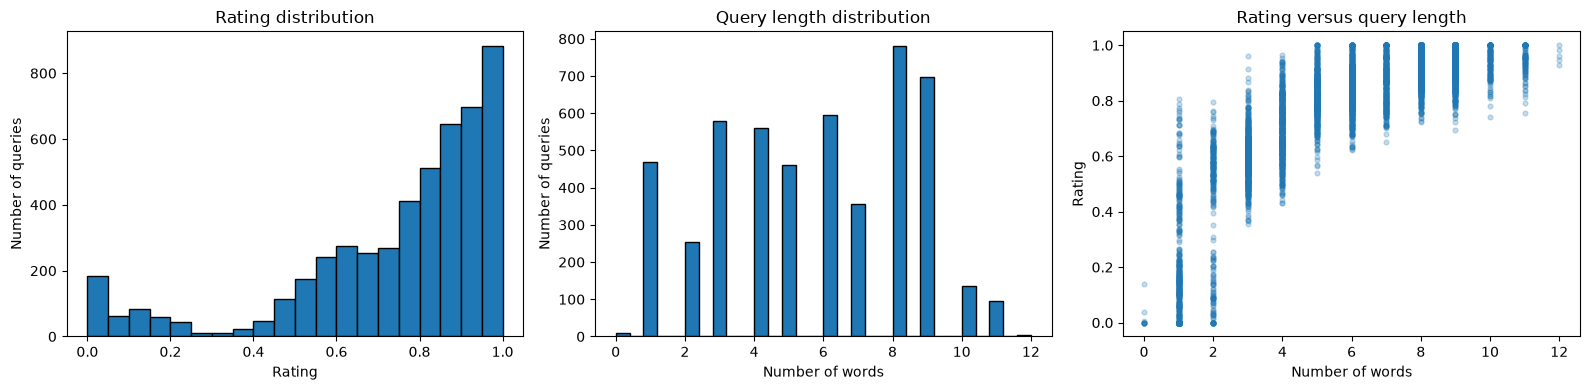

95th-percentile query length: 9
Sequence length used by the neural networks: 10


In [4]:
"""
MODULE 4: EXPLORE RATINGS AND QUERY LENGTHS

Purpose
-------
This module examines the synthetic training data before model training.

The analysis helps answer questions such as:

* Are ratings spread across the 0-to-1 range?
* Are most queries short or long?
* Are there unusually long queries?
* Does query length appear related to rating?
* What sequence length is practical for the neural networks?

Source-data safety
------------------
Word counts and character counts are stored in independent NumPy arrays.
They are not added to the original training DataFrame.

"""

# Count whitespace-separated words.
word_counts = np.array([len(query.split()) for query in model_queries])
# Count individual characters.
character_counts = np.array([len(query) for query in model_queries])

# Display numerical summaries
print("Rating summary:")
display(pd.Series(model_ratings, name="rating").describe())
print("Word-count summary:")
display(pd.Series(word_counts, name="word_count").describe())
print("Character-count summary:")
display(pd.Series(character_counts, name="character_count").describe())

# Create exploratory charts
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(model_ratings, bins=20, edgecolor="black")
axes[0].set(title="Rating distribution", xlabel="Rating", ylabel="Number of queries")
axes[1].hist(word_counts, bins=30, edgecolor="black")
axes[1].set(title="Query length distribution", xlabel="Number of words", ylabel="Number of queries")
axes[2].scatter(word_counts, model_ratings, alpha=0.25, s=12)
axes[2].set(title="Rating versus query length", xlabel="Number of words", ylabel="Rating")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Choose a sequence length
# ---------------------------------------------------------

# The 95th percentile covers most queries while avoiding excessive padding
# caused by a small number of unusually long queries.
length_95 = int(np.ceil(np.percentile(word_counts, 95)))

# Apply lower and upper limits for practical neural-network inputs.
SEQUENCE_LENGTH = int(np.clip(length_95, 10, 100))
print("95th-percentile query length:", length_95)
print("Sequence length used by the neural networks:", SEQUENCE_LENGTH)

In [5]:
"""
MODULE 5: CREATE TRAINING AND VALIDATION GROUPS

Purpose
-------
This module divides labeled observations into training and validation groups.

Training group
--------------
The training group is shown to the model while its weights are being learned.

Validation group
----------------
The validation group is not used to update model weights. It estimates how
well the model handles labeled examples that it did not train on.

Why the split is necessary
--------------------------
Evaluating a model only on information it already trained on can result in an
overly optimistic score.

Test-set protection
-------------------
The queries from test.csv are not included in this split. Their true ratings
are unknown, so they are reserved for final predictions.

"""

X_train_text, X_valid_text, y_train, y_valid = train_test_split(
    model_queries,
    model_ratings,
    test_size=VALIDATION_SIZE,
    random_state=SEED
)

print("Training observations:", len(X_train_text))
print("Validation observations:", len(X_valid_text))
print("Final test observations:", len(test_queries))
print("Average training rating:", round(float(np.mean(y_train)), 4))
print("Average validation rating:", round(float(np.mean(y_valid)), 4))

Training observations: 4000
Validation observations: 1000
Final test observations: 999
Average training rating: 0.7418
Average validation rating: 0.7483


In [6]:
"""
MODULE 6: BUILD REFERENCE BASELINES

Purpose
-------
This module evaluates two simple modeling approaches before training neural
networks.

Why baselines matter
--------------------
A more complicated model should be compared with simpler alternatives.

If a neural network cannot improve on a basic method, its additional
complexity may not provide meaningful value.

Mean baseline
-------------
The mean baseline predicts the average training rating for every validation
query. It does not inspect query text.

TF-IDF plus Ridge baseline
--------------------------
Character-level TF-IDF converts text fragments into numerical features.
Ridge regression learns a regularized linear relationship between those
features and the ratings.

This baseline is included as a comparison. The final required model remains
a neural network.

"""

# Mean baseline
training_mean = float(np.mean(y_train))
mean_predictions = np.full(len(y_valid), training_mean, dtype="float32")
mean_baseline_mae = mean_absolute_error(y_valid, mean_predictions)

# TF-IDF plus Ridge baseline
tfidf_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=2,
    max_features=50_000,
    sublinear_tf=True
)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)
X_valid_tfidf = tfidf_vectorizer.transform(X_valid_text)
ridge_model = Ridge(alpha=3.0)
ridge_model.fit(X_train_tfidf, y_train)
ridge_predictions = np.clip(ridge_model.predict(X_valid_tfidf), 0.0, 1.0)
ridge_baseline_mae = mean_absolute_error(y_valid, ridge_predictions)

print(f"Mean baseline validation MAE: {mean_baseline_mae:.6f}")
print(f"TF-IDF plus Ridge validation MAE: {ridge_baseline_mae:.6f}")

Mean baseline validation MAE: 0.190352
TF-IDF plus Ridge validation MAE: 0.067539


In [7]:
"""
MODULE 7: LEARN TEXT VECTORIZATION AND PRECOMPUTE TOKEN SEQUENCES

Purpose
-------
Neural networks require numbers rather than ordinary words. TextVectorization
learns a vocabulary and maps each query to a fixed-length integer sequence.

Why preprocessing is outside the serialized model
--------------------------------------------------
The mock data includes multilingual Unicode text. Serializing a model that
contained the learned TextVectorization vocabulary triggered a Windows cp1252
encoding error. This notebook therefore precomputes integer sequences and
serializes only the neural network that consumes those sequences.

Data-leakage protection
-----------------------
The evaluation vocabulary is learned from the training partition only. The
validation and test queries do not influence vocabulary learning during model
selection.
"""

vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH,
    standardize="lower_and_strip_punctuation",
    split="whitespace",
    encoding="utf-8",
    name="text_vectorizer"
)

# Learn vocabulary only from training text.
vectorizer.adapt(tf.data.Dataset.from_tensor_slices(X_train_text).batch(256))
VOCAB_SIZE = len(vectorizer.get_vocabulary())

# Precompute integer sequences.
X_train = vectorizer(tf.constant(X_train_text)).numpy()
X_valid = vectorizer(tf.constant(X_valid_text)).numpy()

print("Vocabulary size:", VOCAB_SIZE)
print("Vectorized training shape:", X_train.shape)
print("Vectorized validation shape:", X_valid.shape)
print("Example query:", repr(X_train_text[0]))
print("Example token sequence:", X_train[0])

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Vocabulary size: 711
Vectorized training shape: (4000, 10)
Vectorized validation shape: (1000, 10)
Example query: 'compare printer prices and features'
Example token sequence: [ 83 212  76  72  73   0   0   0   0   0]


In [8]:
"""
MODULE 8: DEFINE SERIALIZABLE NEURAL-NETWORK ARCHITECTURES

Purpose
-------
This module defines two candidate neural networks that accept integer token
sequences. Because the models contain only standard numerical Keras layers,
they can be saved as complete `.keras` artifacts without serializing the
Unicode vocabulary inside the model.

Whole-model serialization
-------------------------
A complete `.keras` save packages the network architecture, learned weights,
compilation information, and optimizer state. The separately saved vectorizer
artifacts reconstruct the raw-text preprocessing step.
"""

def compile_model(model):
    """
    Configure a Keras neural network for query-rating regression.

    Parameters
    ----------
    model : keras.Model
        A Keras model whose layer architecture has already been defined.

        The model must accept integer token sequences and produce one numeric
        prediction for each sequence.

    Returns
    -------
    keras.Model
        The same model after its optimizer, loss function, and evaluation
        metric have been configured.

    Optimizer
    ---------
    Adam is used to adjust the model's trainable weights.

    The learning rate of 0.001 controls the initial size of those updates.

    Loss function
    -------------
    Mean Absolute Error is used as the training objective.

    For one example:

        absolute error = |actual rating - predicted rating|

    The loss is the average of these absolute errors across a batch.

    Metric
    ------
    MAE is also recorded as a named metric so training and validation results
    can be monitored after every epoch.

    Why compilation is separate
    ---------------------------
    A helper function allows both candidate architectures to use exactly the
    same optimizer, loss function, and evaluation metric. This makes their
    comparison more consistent.

    """
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.MeanAbsoluteError(),
        metrics=[keras.metrics.MeanAbsoluteError(name="mae")]
    )
    return model


def build_average_model():
    """
    Build and compile the average-pooling query-rating neural network.

    Returns
    -------
    keras.Model
        A compiled Keras model that accepts an integer matrix of shape:

            (number_of_queries, SEQUENCE_LENGTH)

        and returns one rating between 0 and 1 for each query.

    Architecture
    ------------
    1. Input layer:
       Receives a fixed-length sequence of integer token identifiers.

    2. Embedding layer:
       Converts each token identifier into a learned numerical vector.

    3. Global average pooling:
       Averages all token vectors into one fixed-size query representation.

    4. Dense layers:
       Learn nonlinear relationships between the averaged representation and
       the target rating.

    5. Dropout:
       Randomly disables a proportion of hidden units during training to
       reduce overfitting.

    6. Sigmoid output:
       Produces a value constrained to approximately the interval from 0 to 1.

    Advantages
    ----------
    This model is compact, relatively fast, and often resistant to overfitting.

    Limitation
    ----------
    Average pooling does not explicitly preserve token order. Queries with the
    same tokens in different orders may receive similar representations.

    Serialization
    -------------
    The model contains only standard numerical Keras layers and can therefore
    be saved as a complete `.keras` model without embedding the multilingual
    text vocabulary inside it.

    """
    token_input = keras.Input(
        shape=(SEQUENCE_LENGTH,),
        dtype=tf.int64,
        name="token_sequence"
    )
    x = layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM, mask_zero=True, name="embedding")(token_input)
    x = layers.GlobalAveragePooling1D(name="average_pooling")(x)
    x = layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(0.0001),
        name="dense_64"
    )(x)
    x = layers.Dropout(0.30, name="dropout_30")(x)
    x = layers.Dense(32, activation="relu", name="dense_32")(x)
    x = layers.Dropout(0.20, name="dropout_20")(x)
    output = layers.Dense(1, activation="sigmoid", name="rating")(x)
    return compile_model(keras.Model(token_input, output, name="AveragePoolingNN"))


def build_bigru_model():
    """
    Build and compile the bidirectional-GRU query-rating neural network.

    Returns
    -------
    keras.Model
        A compiled Keras model that accepts a fixed-length integer token
        sequence and produces one rating between 0 and 1.

    Architecture
    ------------
    1. Input layer:
       Receives integer token sequences.

    2. Embedding layer:
       Converts tokens into learned numerical representations.

    3. Bidirectional GRU:
       Processes the sequence in both forward and reverse directions.

       GRU stands for Gated Recurrent Unit. It is a recurrent neural-network
       component designed to model sequence relationships.

    4. Dense hidden layer:
       Learns nonlinear relationships from the sequence representation.

    5. Dropout:
       Reduces overfitting by randomly disabling hidden units during training.

    6. Sigmoid output:
       Produces a rating constrained to approximately 0 through 1.

    Advantages
    ----------
    Unlike average pooling, the GRU can use token order and surrounding
    context.

    Tradeoff
    --------
    The model is more computationally expensive and may overfit more easily
    than the average-pooling architecture.

    Serialization
    -------------
    This model contains only numerical Keras layers. The multilingual
    vocabulary remains outside the `.keras` artifact.

    """
    token_input = keras.Input(
        shape=(SEQUENCE_LENGTH,),
        dtype=tf.int64,
        name="token_sequence"
    )
    x = layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM, mask_zero=True, name="embedding")(token_input)
    x = layers.Bidirectional(
        layers.GRU(48, dropout=0.20),
        name="bidirectional_gru"
    )(x)
    x = layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(0.0001),
        name="dense_64"
    )(x)
    x = layers.Dropout(0.35, name="dropout_35")(x)
    output = layers.Dense(1, activation="sigmoid", name="rating")(x)
    return compile_model(keras.Model(token_input, output, name="BidirectionalGRUNN"))

# Store architecture-building functions in one dictionary.
model_builders = {
    "AveragePoolingNN": build_average_model,
    "BidirectionalGRUNN": build_bigru_model
}

# Display one architecture before training.
preview_model = build_average_model()
preview_model.summary()
del preview_model

Model: "AveragePoolingNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ token_sequence (InputLayer)          │ (None, 10)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ embedding (Embedding)                │ (None, 10, 64)              │          45,504 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ average_pooling                      │ (None, 64)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_64 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_30 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_32 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_20 (Dropout)                 │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rating (Dense)                       │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 51,777 (202.25 KB)

 Trainable params: 51,777 (202.25 KB)

 Non-trainable params: 0 (0.00 B)


Training: AveragePoolingNN
Epoch 1/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: nan - mae: 0.2847
Epoch 1: val_loss improved from None to nan, saving model to outputs\AveragePoolingNN_best.keras

Epoch 1: finished saving model to outputs\AveragePoolingNN_best.keras
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - loss: nan - mae: 0.2847 - val_loss: nan - val_mae: 0.2479 - learning_rate: 0.0010
Epoch 2/25
56/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: nan - mae: 0.2215
Epoch 2: val_loss did not improve from nan
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: nan - mae: 0.2200 - val_loss: nan - val_mae: 0.1948 - learning_rate: 0.0010
Epoch 3/25
51/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: nan - mae: 0.1892
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 3: val_loss did not improve from nan
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: nan - mae: 0.1888 - val_loss: nan - val_mae: 0.1780 - learning_rate: 0.0010
Epoch 4/25
52/63 ━━━━━━━━━━━━━━━━━━━━ 0s 

,model,validation_mae,best_epoch,parameters,checkpoint_path
0,BidirectionalGRUNN,0.058763,22,84609,outputs\BidirectionalGRUNN_best.keras
1,AveragePoolingNN,0.247871,1,51777,outputs\AveragePoolingNN_best.keras


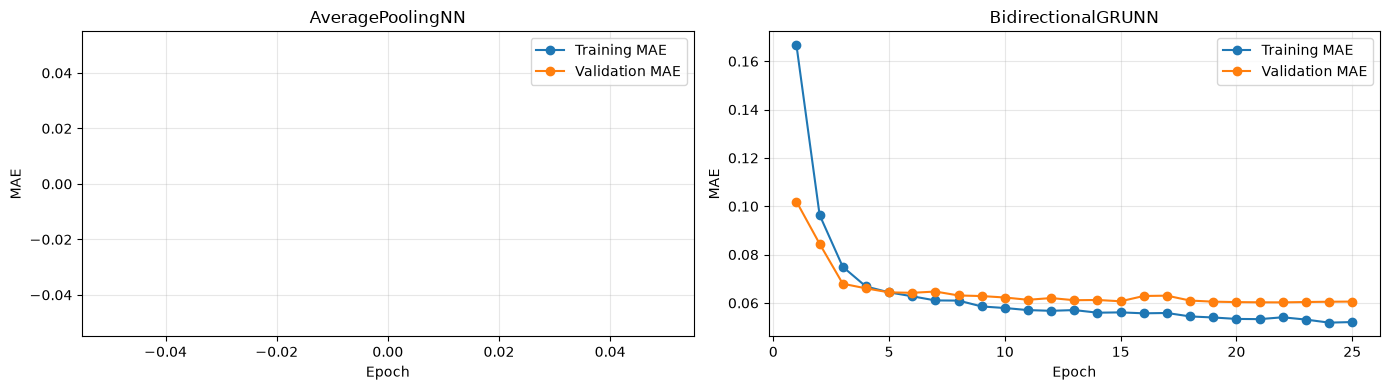

Selected neural network: BidirectionalGRUNN
Best epoch: 22
Validation MAE: 0.058763


,model,validation_mae
0,BidirectionalGRUNN,0.058763
1,TF-IDF plus Ridge,0.067539
2,Mean baseline,0.190352


In [9]:
"""
MODULE 9: TRAIN, CHECKPOINT, AND COMPARE THE NEURAL NETWORKS

Purpose
-------
This module trains both candidate architectures under the same conditions.

Overfitting protection
----------------------
EarlyStopping:
    Stops training after validation loss stops improving and restores the best
    in-memory weights.

ReduceLROnPlateau:
    Reduces the learning rate after validation progress stalls.

ModelCheckpoint:
    Saves the complete best-performing version of each candidate model as a
    `.keras` file.

Why whole-model checkpoints are safe here
-----------------------------------------
The checkpointed models contain numerical neural-network layers only.

The multilingual vocabulary is not contained inside them, so Keras does not
need to serialize the vocabulary using the problematic Windows encoding.

"""

histories = {}
trained_models = {}
experiment_results = []
checkpoint_paths = {}

for model_name, build_model in model_builders.items():
    print("\n" + "=" * 75)
    print("Training:", model_name)

    tf.keras.utils.set_random_seed(SEED)
    model = build_model()
    checkpoint_path = OUTPUT_DIR / f"{model_name}_best.keras"
    checkpoint_paths[model_name] = checkpoint_path

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            min_delta=0.0001,
            restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=0.000001,
            verbose=1
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=checkpoint_path,
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            save_weights_only=False,
            verbose=1
        )
    ]

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_valid, y_valid),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=1
    )

    # Reload the saved checkpoint to prove that the complete model archive
    # can be restored successfully.
    restored_candidate = keras.models.load_model(checkpoint_path)
    validation_predictions = np.clip(
        restored_candidate.predict(X_valid, batch_size=BATCH_SIZE, verbose=0).reshape(-1),
        0.0,
        1.0
    )
    validation_mae = mean_absolute_error(y_valid, validation_predictions)
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

    histories[model_name] = history.history
    trained_models[model_name] = restored_candidate
    experiment_results.append({
        "model": model_name,
        "validation_mae": validation_mae,
        "best_epoch": best_epoch,
        "parameters": restored_candidate.count_params(),
        "checkpoint_path": str(checkpoint_path)
    })

# Compare neural-network experiments
results_df = pd.DataFrame(experiment_results).sort_values("validation_mae").reset_index(drop=True)
display(results_df)

# Plot learning curves
fig, axes = plt.subplots(1, len(histories), figsize=(7 * len(histories), 4), squeeze=False)
for axis, (model_name, history) in zip(axes.ravel(), histories.items()):
    epochs = np.arange(1, len(history["loss"]) + 1)
    axis.plot(epochs, history["loss"], marker="o", label="Training MAE")
    axis.plot(epochs, history["val_loss"], marker="o", label="Validation MAE")
    axis.set(title=model_name, xlabel="Epoch", ylabel="MAE")
    axis.grid(alpha=0.3)
    axis.legend()
plt.tight_layout()
plt.show()

# Select the best neural network
best_model_name = results_df.loc[0, "model"]
best_model = trained_models[best_model_name]
best_neural_mae = float(results_df.loc[0, "validation_mae"])
best_epoch = int(results_df.loc[0, "best_epoch"])

overall_comparison = pd.DataFrame({
    "model": ["Mean baseline", "TF-IDF plus Ridge", best_model_name],
    "validation_mae": [mean_baseline_mae, ridge_baseline_mae, best_neural_mae]
}).sort_values("validation_mae").reset_index(drop=True)

print("Selected neural network:", best_model_name)
print("Best epoch:", best_epoch)
print(f"Validation MAE: {best_neural_mae:.6f}")
display(overall_comparison)

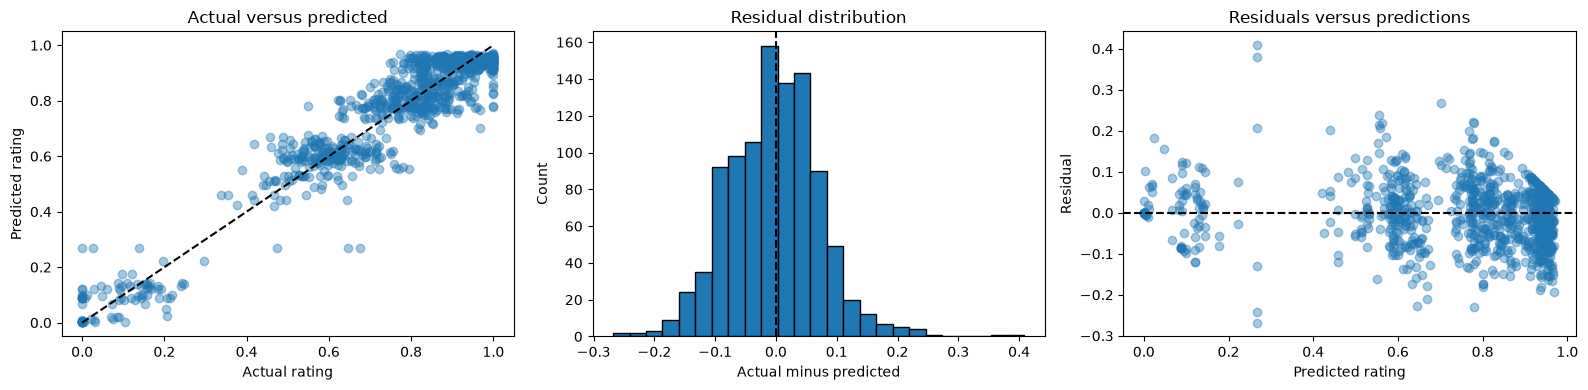

Validation MAE: 0.058763
Mean residual: -0.003382
Largest absolute error: 0.408553


In [10]:
"""
MODULE 10: DIAGNOSE VALIDATION PERFORMANCE

Purpose
-------
This module examines the selected neural network in more detail.

Why MAE alone is not enough
---------------------------
MAE summarizes the model's typical prediction error, but it does not show:

* whether predictions are systematically too high or too low,
* whether errors are concentrated in one rating range, or
* whether a small number of observations have unusually large errors.

Residual definition
-------------------
A residual is calculated as:

    actual rating - predicted rating

A positive residual means the model predicted too low.

A negative residual means the model predicted too high.

"""

best_validation_predictions = np.clip(
    best_model.predict(X_valid, batch_size=BATCH_SIZE, verbose=0).reshape(-1),
    0.0,
    1.0
)
residuals = y_valid - best_validation_predictions

# Diagnostic charts
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(y_valid, best_validation_predictions, alpha=0.4)
axes[0].plot([0, 1], [0, 1], color="black", linestyle="--")
axes[0].set(title="Actual versus predicted", xlabel="Actual rating", ylabel="Predicted rating")
axes[1].hist(residuals, bins=25, edgecolor="black")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set(title="Residual distribution", xlabel="Actual minus predicted", ylabel="Count")
axes[2].scatter(best_validation_predictions, residuals, alpha=0.4)
axes[2].axhline(0, color="black", linestyle="--")
axes[2].set(title="Residuals versus predictions", xlabel="Predicted rating", ylabel="Residual")
plt.tight_layout()
plt.show()

print(f"Validation MAE: {mean_absolute_error(y_valid, best_validation_predictions):.6f}")
print(f"Mean residual: {float(np.mean(residuals)):.6f}")
print(f"Largest absolute error: {float(np.max(np.abs(residuals))):.6f}")

In [11]:
"""
MODULE 11: REFIT THE SELECTED ARCHITECTURE ON ALL LABELED DATA

Purpose
-------
After selecting the best architecture, this module rebuilds the preprocessing
pipeline and selected neural network using all usable labeled observations.

Why refit?
----------
The validation group was withheld during model selection.

Once the architecture and training duration have been selected, those labeled
observations can contribute to final training.

Final vocabulary
----------------
The final TextVectorization layer learns from every usable labeled query.

Because this vocabulary may differ from the evaluation vocabulary, a new final
model is created and trained against the new integer sequences.

Preprocessing artifacts
-----------------------
The vectorizer settings and ordered vocabulary are saved as UTF-8 JSON.

These files are needed because the serialized neural model expects integer
sequences rather than raw strings.
"""

# Build and adapt the final vectorizer
final_vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH,
    standardize="lower_and_strip_punctuation",
    split="whitespace",
    encoding="utf-8",
    name="text_vectorizer"
)
final_vectorizer.adapt(tf.data.Dataset.from_tensor_slices(model_queries).batch(256))

# Capture vocabulary and create final sequences
final_vocabulary = final_vectorizer.get_vocabulary()
VOCAB_SIZE = len(final_vocabulary)
final_train_sequences = final_vectorizer(tf.constant(model_queries)).numpy()
final_test_sequences = final_vectorizer(tf.constant(test_queries)).numpy()

# Save preprocessing artifacts explicitly as UTF-8 JSON.
vectorizer_config = {
    "max_tokens": MAX_TOKENS,
    "output_mode": "int",
    "output_sequence_length": SEQUENCE_LENGTH,
    "standardize": "lower_and_strip_punctuation",
    "split": "whitespace",
    "encoding": "utf-8"
}

# Save the exact ordered vocabulary
with open(VECTORIZER_CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(vectorizer_config, file, indent=2, ensure_ascii=False)
with open(VECTORIZER_VOCABULARY_PATH, "w", encoding="utf-8") as file:
    json.dump(final_vocabulary, file, indent=2, ensure_ascii=False)

# Build and train the final neural network
# The builders now read the final VOCAB_SIZE.
tf.keras.utils.set_random_seed(SEED)
final_model = model_builders[best_model_name]()
final_model.fit(
    final_train_sequences,
    model_ratings,
    epochs=best_epoch,
    batch_size=BATCH_SIZE,
    verbose=1
)

print("Final vocabulary size:", VOCAB_SIZE)
print("Final training sequence shape:", final_train_sequences.shape)

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
Epoch 1/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 77ms/step - loss: 0.1518 - mae: 0.1454
Epoch 2/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0879 - mae: 0.0828
Epoch 3/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 0.0698 - mae: 0.0651
Epoch 4/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0654 - mae: 0.0614
Epoch 5/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0622 - mae: 0.0587
Epoch 6/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0618 - mae: 0.0587
Epoch 7/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0604 - mae: 0.0576
Epoch 8/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.0600 - mae: 0.0574
Epoch 9/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0584 - mae: 0.0560
Epoch 10/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0591 - mae: 0.0569
Epoch 11/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0581 - mae: 0.0561
Epoch 12/22
79/79 ━━━━━━━━━━━━━━━━━━━━

In [12]:
"""
MODULE 12: PREDICT, SERIALIZE THE WHOLE MODEL, AND SAVE OUTPUTS

Purpose
-------
This module generates final test predictions and saves all required outputs.

Saved artifacts
---------------
submission.csv:
    Contains the test queries and their predicted ratings.

model_experiment_results.csv:
    Contains validation results for the candidate models.

best_query_rating_model.keras:
    Contains the complete final numerical neural network.

text_vectorizer_config.json:
    Contains the settings needed to reconstruct text preprocessing.

text_vectorizer_vocabulary.json:
    Contains the ordered UTF-8 vocabulary.

What the `.keras` model contains
--------------------------------
The complete neural-model archive contains:

* architecture,
* layer configuration,
* trained weights,
* compilation configuration, and
* optimizer state.

What it does not contain
------------------------
The model does not contain TextVectorization or raw vocabulary text.

It expects integer token sequences produced by the separately reconstructed
vectorizer.
"""

# Generate predictions
test_predictions = np.clip(
    final_model.predict(final_test_sequences, batch_size=BATCH_SIZE, verbose=0).reshape(-1),
    0.0,
    1.0
)

# Create a separate submission table
submission_output = pd.DataFrame({
    "query": test_data["query"].to_numpy(copy=True),
    "rating": test_predictions.astype(float)
})

# Validate the submission
assert list(submission_output.columns) == ["query", "rating"]
assert len(submission_output) == len(test_data)
assert submission_output["rating"].notna().all()
assert submission_output["rating"].between(0.0, 1.0).all()
assert submission_output["query"].equals(test_data["query"])

# Verify the input DataFrames still have their original structures.
assert tuple(data.columns) == original_train_columns
assert tuple(test_data.columns) == original_test_columns
assert data.shape == original_train_shape
assert test_data.shape == original_test_shape

# Save project outputs
submission_output.to_csv(SUBMISSION_PATH, index=False, encoding="utf-8")
results_df.to_csv(RESULTS_PATH, index=False, encoding="utf-8")

# Whole-model serialization should now succeed because final_model contains
# only numerical Keras layers and does not contain the Unicode vocabulary.
final_model.save(FINAL_MODEL_PATH)

print("Submission saved to:", SUBMISSION_PATH.resolve())
print("Experiment results saved to:", RESULTS_PATH.resolve())
print("Whole Keras model saved to:", FINAL_MODEL_PATH.resolve())
print("Vectorizer config saved to:", VECTORIZER_CONFIG_PATH.resolve())
print("Vectorizer vocabulary saved to:", VECTORIZER_VOCABULARY_PATH.resolve())
display(submission_output.head())

Submission saved to: C:\Drive_D\Gia Huy\pythonfiles\HoneywellAIEngineerassessment\outputs\submission.csv
Experiment results saved to: C:\Drive_D\Gia Huy\pythonfiles\HoneywellAIEngineerassessment\outputs\model_experiment_results.csv
Whole Keras model saved to: C:\Drive_D\Gia Huy\pythonfiles\HoneywellAIEngineerassessment\outputs\best_query_rating_model.keras
Vectorizer config saved to: C:\Drive_D\Gia Huy\pythonfiles\HoneywellAIEngineerassessment\outputs\text_vectorizer_config.json
Vectorizer vocabulary saved to: C:\Drive_D\Gia Huy\pythonfiles\HoneywellAIEngineerassessment\outputs\text_vectorizer_vocabulary.json


,query,rating
0,NaN,0.056879
1,x,0.000921
2,?,0.056879
3,12345,0.231249
4,weather,0.341124


In [13]:
"""
MODULE 13: RESTORE AND VERIFY THE COMPLETE PREDICTION PIPELINE

Purpose
-------
A saved model should not be considered reliable until it has been loaded and
tested.

This module reconstructs the full prediction pipeline from disk.

Restoration steps
-----------------
1. Read the vectorizer configuration as UTF-8 JSON.
2. Read the ordered vocabulary as UTF-8 JSON.
3. Reconstruct TextVectorization.
4. Load the complete `.keras` neural model.
5. Transform sample raw queries into integer sequences.
6. Generate predictions with the restored model.
7. Compare restored predictions with the original predictions.

Why prediction comparison matters
---------------------------------
Successfully loading a file is not enough.

Matching predictions confirm that:

* preprocessing was reconstructed correctly,
* token identifiers retain the same meanings,
* the model architecture was restored,
* the trained weights were restored, and
* the combined pipeline behaves as expected.
"""

# Load vectorizer settings
with open(VECTORIZER_CONFIG_PATH, "r", encoding="utf-8") as file:
    restored_config = json.load(file)
with open(VECTORIZER_VOCABULARY_PATH, "r", encoding="utf-8") as file:
    restored_vocabulary = json.load(file)

# TextVectorization automatically creates the reserved mask and unknown-token
# entries for integer output. get_vocabulary() places them first, so provide
# only the learned tokens when reconstructing the layer.
restored_vectorizer = layers.TextVectorization(
    max_tokens=restored_config["max_tokens"],
    output_mode=restored_config["output_mode"],
    output_sequence_length=restored_config["output_sequence_length"],
    standardize=restored_config["standardize"],
    split=restored_config["split"],
    encoding=restored_config["encoding"],
    vocabulary=restored_vocabulary[2:],
    name="text_vectorizer"
)

# Confirm that every token returned to its original position.
assert restored_vectorizer.get_vocabulary() == restored_vocabulary

# Load the complete neural model
restored_model = keras.models.load_model(FINAL_MODEL_PATH)

# Reproduce sample predictions
restored_sample_sequences = restored_vectorizer(tf.constant(test_queries[:20])).numpy()
restored_sample_predictions = np.clip(
    restored_model.predict(restored_sample_sequences, batch_size=BATCH_SIZE, verbose=0).reshape(-1),
    0.0,
    1.0
)

# Compare original and restored predictions.
assert np.allclose(
    test_predictions[:20],
    restored_sample_predictions,
    atol=0.000001
), "Restored predictions do not match the original predictions."

comparison_sample = pd.DataFrame({
    "query": test_data["query"].head(20),
    "original_prediction": test_predictions[:20],
    "restored_prediction": restored_sample_predictions
})

display(comparison_sample)
print("Whole-model restoration verification passed.")

,query,original_prediction,restored_prediction
0,NaN,0.056879,0.056879
1,x,0.000921,0.000921
2,?,0.056879,0.056879
3,12345,0.231249,0.231249
4,weather,0.341124,0.341124
5,weather tomorrow,0.577633,0.577633
6,WEATHER TOMORROW,0.577633,0.577633
7,weather tomorrow,0.577633,0.577633
8,how to learn Python as a complete beginner,0.928846,0.928846
9,how 2 learn python fast,0.751407,0.751407


Whole-model restoration verification passed.
